In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rich.jupyter import display

In [39]:
path = "C:/Users/infomax/Downloads/"
file = "IRSCRS_basis_2y.csv"
filename = path + file

In [40]:
print(filename)

C:/Users/infomax/Downloads/IRSCRS_basis_2y.csv


In [49]:
basis = pd.read_csv(file, parse_dates=['Date'], index_col='Date')

delta = basis["BASIS"].diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.ewm(alpha=1 / 14, min_periods=14, adjust=False).mean()
avg_loss = loss.ewm(alpha=1 / 14, min_periods=14, adjust=False).mean()
rs = avg_gain / avg_loss.replace(0, np.nan)

basis["RSI"] = 100 - (100 / (1 + rs))
basis.loc[(avg_loss == 0) & (avg_gain > 0), "RSI"] = 100
basis.loc[(avg_loss == 0) & (avg_gain == 0), "RSI"] = 50

In [51]:
basis.head()

,CRS,IRS,BASIS,RSI
Date,,,,
2026-05-08,3.015,3.5475,-53.25,NaN
2026-05-07,3.010,3.5325,-52.25,NaN
2026-05-06,3.055,3.5900,-53.50,NaN
2026-05-04,3.070,3.6375,-56.75,NaN
2026-04-30,3.060,3.6300,-57.00,NaN


,CRS,IRS,BASIS,RSI
Date,,,,
2026-05-08,3.015,3.5475,-53.25,NaN
2026-05-07,3.010,3.5325,-52.25,NaN
2026-05-06,3.055,3.5900,-53.50,NaN
2026-05-04,3.070,3.6375,-56.75,NaN
2026-04-30,3.060,3.6300,-57.00,NaN


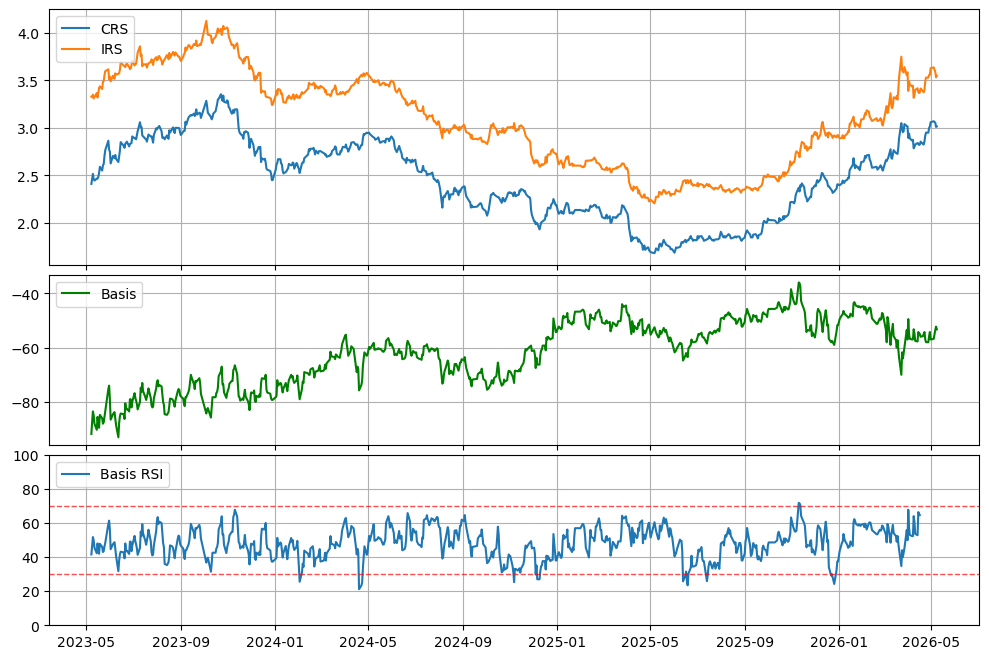

In [62]:
display(basis.head())

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 8), sharex=True, height_ratios=(1.5, 1, 1))
ax1.plot(basis[["CRS", "IRS"]], label=["CRS", "IRS"])
ax2.plot(basis["BASIS"], label="Basis", color='g')
ax3.plot(basis["RSI"], label="Basis RSI")
ax3.axhline(30, color='r', linestyle='--', linewidth=1, alpha=0.7)
ax3.axhline(70, color='r', linestyle='--', linewidth=1, alpha=0.7)
ax3.set_ylim(0, 100)

fig.subplots_adjust(hspace=0.05)

ax1.grid()
ax1.legend(loc='upper left')
ax2.grid()
ax2.legend(loc='upper left')
ax3.grid()
ax3.legend(loc='upper left')
plt.show()

In [53]:
basis

,CRS,IRS,BASIS,RSI
Date,,,,
2026-05-08,3.015,3.5475,-53.25,NaN
2026-05-07,3.010,3.5325,-52.25,NaN
2026-05-06,3.055,3.5900,-53.50,NaN
2026-05-04,3.070,3.6375,-56.75,NaN
2026-04-30,3.060,3.6300,-57.00,NaN
...,...,...,...,...
2023-05-12,2.445,3.3250,-88.00,45.609616
2023-05-11,2.460,3.3100,-85.00,49.782929
2023-05-10,2.515,3.3500,-83.50,51.775356


In [72]:
s = pd.Series([-3, -1, np.nan, 2, 5])

In [73]:
s.clip(lower = 0).to_list()

[0.0, 0.0, nan, 2.0, 5.0]

In [74]:
s.clip(upper = 0).to_list()

[-3.0, -1.0, nan, 0.0, 0.0]

In [83]:
temp = basis.drop(columns="RSI").copy()

In [86]:
delta = temp["BASIS"].diff()

Date
2026-05-08     NaN
2026-05-07    1.00
2026-05-06    0.00
2026-05-04    0.00
2026-04-30    0.00
              ... 
2023-05-12    2.25
2023-05-11    3.00
2023-05-10    1.50
2023-05-09    0.00
2023-05-08    0.00
Name: BASIS, Length: 727, dtype: float64